##Expanded Classification

This notebook investigates whether including additional job posting details such as the company profile improves performance compared with using only the job description.

The experiments will initially focus on company profile text followed by selected features such as whether the posting includes a company profile and company logo.

Models will use the same training/test split built in the baseline notebook to maintain consistency.

In [3]:
#most of the requirements for the notebook
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

In [4]:
#grabs the cleaned dataset and postings split from the notebooks 1 and 2
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv(
    '/content/drive/MyDrive/fake_job_postings_cleaned.csv'
)

split_assignments = pd.read_csv(
    '/content/drive/MyDrive/job_posting_split.csv'
)

#shapes should be (17880,23) and (17878, 2)
print("Dataset shape:", df.shape)
print("Saved split assignments:", split_assignments.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (17880, 23)
Saved split assignments: (17878, 2)


In [5]:
#adds the other text fields such as benefits and requirements to the split data used to train on only the description. Merges using the job_id column
#using the same split provides a fair comparison to the description only performance
model_df = df.merge(
    split_assignments,
    on='job_id',
    how='inner',
    validate='one_to_one'
)

#displays the size of the dataset and the size of train, test
print("Modeling dataset:", model_df.shape)
print(model_df['split'].value_counts())

Modeling dataset: (17878, 24)
split
train    14274
test      3604
Name: count, dtype: int64


##Test whether analyzing the job description and company profile text improves fraud detection

In [6]:
#prepares the text columns to be included in the next portion. Will use the description and the company profile
text_columns = [
    'description_repaired',
    'company_profile_repaired'
]
#replaces any missing values with an empty string to ensure the vectorizer does not throw any errors
model_df[text_columns] = (
    model_df[text_columns].fillna('')
)

#creates a dataframe with the training data using the previously made split
train_df = model_df[
    model_df['split'] == 'train'
].copy()
#creates dataframe with test data
test_df = model_df[
    model_df['split'] == 'test'
].copy()
#grabs the target labels for the train and test data (fraudulent=1)
y_train = train_df['fraudulent']
y_test = test_df['fraudulent']

#displays the size of train and test partitions
print("Training:", len(train_df))
print("Testing:", len(test_df))

Training: 14274
Testing: 3604


In [7]:
#creates an additional column "has_company_profile" since fraudulent postings are much more likely to be missing this text. Will be used to test whether simply missing a company profile can be used to predict fraud
model_df['has_company_profile'] = (
    model_df['company_profile_repaired']
    .str.strip()
    .ne('')
    .astype(int)
)

#displays the breakdown of has_company_profile vs fraudulent. Normalizes the values to display a proportion instead of raw counts
print(
    pd.crosstab(
        model_df['fraudulent'],
        model_df['has_company_profile'],
        normalize='index'
    ).round(3)
)

has_company_profile      0      1
fraudulent                       
0                    0.160  0.840
1                    0.678  0.322


In [8]:
#sets up the TF-IDF logistic regression model using the sklearn columntransformer. Vectorizes each field independently since words may be more impactful depending on the field. "Experience" may be more predictive in the "description_repaired" field than "company_profile"

#uses the parameters found to be best in the prior tuning. Converts to lowercase, doesn't remove stopwords, and includes single words and bigrams. Minimum document frequency is 3
text_features = ColumnTransformer([
    (
        'description',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'description_repaired'
    ),
    (
        'company_profile',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'company_profile_repaired'
    )
])

#uses the sklearn pipeline to setup the model training. Uses the columntransformer from above. Uses c=10 for regularization, allows for 1000 iterations, keeps the balanced class weights, and sets the seed
expanded_model = Pipeline([
    ('features', text_features),
    ('classifier', LogisticRegression(
        C=10,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [9]:
#This step takes about 30seconds to 1 min
#uses the sklearn cross validation tools to evaluate the model that uses both the job description and company profile
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

#sets up the cross validation, 5 folds, shuffles the data, sets the seed
#model is tested 5 times and each time it uses 4 folds for training and 1 for validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
#creates a dataframe containing the two fields used by the model
X_train_expanded = train_df[
    ['description_repaired', 'company_profile_repaired']
]
#groups based on the repaired descriptions, that way if there are any identical descriptions they are kept together in training or validation
train_groups = train_df['description_repaired']

#performs the cross validation using the expanded_model built earlier. Uses the x_train_expanded as the predictors, y_train is the actual fraud labels, groups are the train_groups, cv uses the 5 fold defined above, scores precision, recall, and f1, n_jobs tries to improve speed of the operation
expanded_cv = cross_validate(
    expanded_model,
    X_train_expanded,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring={
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print("Expanded model cross-validation results:")

for metric in ['precision', 'recall', 'f1']:
    scores = expanded_cv[f'test_{metric}']

    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(std: {scores.std():.3f})"
    )

Expanded model cross-validation results:
Precision: 0.889 (std: 0.050)
Recall: 0.725 (std: 0.124)
F1: 0.793 (std: 0.076)


In [10]:
#compares the baseline model using only the description with the expanded model that includes the company profile as well

#builds the same model from the previous notebook using the optimized parameters found during testing
baseline_model = Pipeline([
    ('vectorizer', TfidfVectorizer(
        lowercase=True,
        stop_words=None,
        ngram_range=(1, 2),
        min_df=3
    )),
    ('classifier', LogisticRegression(
        C=10,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

#performs cross validation on the baseline model
baseline_cv = cross_validate(
    baseline_model,
    train_df['description_repaired'],
    y_train,
    groups=train_groups,
    cv=cv,
    scoring={
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)
#compares the baseline and expanded model
comparison = pd.DataFrame({
    'Model': [
        'Description Only',
        'Description + Company Profile'
    ],
    'Precision': [
        baseline_cv['test_precision'].mean(),
        expanded_cv['test_precision'].mean()
    ],
    'Recall': [
        baseline_cv['test_recall'].mean(),
        expanded_cv['test_recall'].mean()
    ],
    'F1': [
        baseline_cv['test_f1'].mean(),
        expanded_cv['test_f1'].mean()
    ]
})

display(comparison.round(3))

,Model,Precision,Recall,F1
0,Description Only,0.814,0.528,0.636
1,Description + Company Profile,0.889,0.725,0.793


In [11]:
#loops through training and test data to see if it has the added has_company_profile feature. If it doesnt, it is added
for data in [train_df, test_df]:
    data['has_company_profile'] = (
        data['company_profile_repaired']
        .str.strip()
        .ne('')
        .astype(int)
    )

##Test whether using the job description text and the presence of a company profile is a decent indicator. Does not analyze the company profile text, only that it exists or not

In [12]:
#uses the sklearn column transformer and sets up the vectorizer for the job descriptions and uses the has_company_profile as a binary "exists or not"
presence_features = ColumnTransformer([
    (
        'description',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'description_repaired'
    ),
    (
        'profile_presence',
        'passthrough',
        ['has_company_profile']
    )
])

In [13]:
#sets up the model using the description and company profile indicator. Uses the same parameters as before
presence_model = Pipeline([
    ('features', presence_features),
    ('classifier', LogisticRegression(
        C=10,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [14]:
#trains the validation version of the description and company profile presence model and performs cross validation
X_train_presence = train_df[
    ['description_repaired', 'has_company_profile']
]

presence_cv = cross_validate(
    presence_model,
    X_train_presence,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring={
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print("Description + Profile Presence")

for metric in ['precision', 'recall', 'f1']:
    scores = presence_cv[f'test_{metric}']

    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(std: {scores.std():.3f})"
    )

Description + Profile Presence
Precision: 0.780 (std: 0.021)
Recall: 0.611 (std: 0.127)
F1: 0.677 (std: 0.080)


In [15]:
#builds a comparison chart for each model results
cv_results = {
    'Description Only': baseline_cv,
    'Description + Profile Text': expanded_cv,
    'Description + Profile Presence': presence_cv
}

comparison_rows = []

for name, result in cv_results.items():
    comparison_rows.append({
        'Model': name,
        'Precision': result['test_precision'].mean(),
        'Recall': result['test_recall'].mean(),
        'F1': result['test_f1'].mean()
    })

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(3))

,Model,Precision,Recall,F1
0,Description Only,0.814,0.528,0.636
1,Description + Profile Text,0.889,0.725,0.793
2,Description + Profile Presence,0.780,0.611,0.677


##Test whether using the job description text, company profile text, and company profile indicator improves performance

In [16]:
#repeats previous vectorization setup steps but includes the description text, company profile text, and the profile indicator
combined_features = ColumnTransformer([
    (
        'description',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'description_repaired'
    ),
    (
        'company_profile',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'company_profile_repaired'
    ),
    (
        'profile_presence',
        'passthrough',
        ['has_company_profile']
    )
])

combined_model = Pipeline([
    ('features', combined_features),
    ('classifier', LogisticRegression(
        C=10,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [17]:
#trains the cross validation version of the model and performs cross validation
X_train_combined = train_df[
    [
        'description_repaired',
        'company_profile_repaired',
        'has_company_profile'
    ]
]

combined_cv = cross_validate(
    combined_model,
    X_train_combined,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring={
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print("Description + Profile Text + Profile Presence")

for metric in ['precision', 'recall', 'f1']:
    scores = combined_cv[f'test_{metric}']

    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(std: {scores.std():.3f})"
    )

Description + Profile Text + Profile Presence
Precision: 0.840 (std: 0.039)
Recall: 0.739 (std: 0.129)
F1: 0.780 (std: 0.077)


In [18]:
#adds the new results to the table
cv_results['Description + Profile Text + Presence'] = combined_cv

comparison_rows = []

for name, result in cv_results.items():
    comparison_rows.append({
        'Model': name,
        'Precision': result['test_precision'].mean(),
        'Recall': result['test_recall'].mean(),
        'F1': result['test_f1'].mean()
    })

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(3))

,Model,Precision,Recall,F1
0,Description Only,0.814,0.528,0.636
1,Description + Profile Text,0.889,0.725,0.793
2,Description + Profile Presence,0.780,0.611,0.677
3,Description + Profile Text + Presence,0.840,0.739,0.780


##Analyze the company logo since fraudulent postings more frequently lack them

In [ ]:
#display the breakdown of postings that have a company logo vs their fraudulent status (fraudulent=1)
pd.crosstab(
    model_df['fraudulent'],
    model_df['has_company_logo'],
    normalize='index'
).round(3)

has_company_logo,0,1
fraudulent,,
0,0.181,0.819
1,0.674,0.326


In [19]:
#sets up the vectorization of the description text, company profile text, and uses the company logo indicator
logo_features = ColumnTransformer([
    (
        'description',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'description_repaired'
    ),
    (
        'company_profile',
        TfidfVectorizer(
            lowercase=True,
            stop_words=None,
            ngram_range=(1, 2),
            min_df=3
        ),
        'company_profile_repaired'
    ),
    (
        'company_logo',
        'passthrough',
        ['has_company_logo']
    )
])

logo_model = Pipeline([
    ('features', logo_features),
    ('classifier', LogisticRegression(
        C=10,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [20]:
#trains the cross validation version of the model of description, profile, and logo indicator
X_train_logo = train_df[
    [
        'description_repaired',
        'company_profile_repaired',
        'has_company_logo'
    ]
]

#performs cross validation
logo_cv = cross_validate(
    logo_model,
    X_train_logo,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring={
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print("Description + Profile Text + Company Logo")

for metric in ['precision', 'recall', 'f1']:
    scores = logo_cv[f'test_{metric}']

    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(std: {scores.std():.3f})"
    )

Description + Profile Text + Company Logo
Precision: 0.853 (std: 0.022)
Recall: 0.756 (std: 0.125)
F1: 0.797 (std: 0.079)


In [21]:
#adds the new model results to the table
cv_results['Description + Profile Text + Logo'] = logo_cv

comparison = pd.DataFrame([
    {
        'Model': name,
        'Precision': result['test_precision'].mean(),
        'Recall': result['test_recall'].mean(),
        'F1': result['test_f1'].mean()
    }
    for name, result in cv_results.items()
])

display(comparison.round(3))

,Model,Precision,Recall,F1
0,Description Only,0.814,0.528,0.636
1,Description + Profile Text,0.889,0.725,0.793
2,Description + Profile Presence,0.780,0.611,0.677
3,Description + Profile Text + Presence,0.840,0.739,0.780
4,Description + Profile Text + Logo,0.853,0.756,0.797


##Test whether including the job requirements text and benefits text improves performance

In [22]:
#loops through the cleaned requirements and benefits columns of the training and test data and replaces missing values with empty strings to ensure the vectorizer runs smoothly
additional_text_columns = [
    'requirements_repaired',
    'benefits_repaired'
]

for data in [train_df, test_df]:
    data[additional_text_columns] = (
        data[additional_text_columns].fillna('')
    )

In [24]:
#sets up the vectorizer for the description text, company profile text, requirements text, benefits text, and uses the company logo indicator
full_text_features = ColumnTransformer([
    (
        'description',
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=3
        ),
        'description_repaired'
    ),
    (
        'company_profile',
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=3
        ),
        'company_profile_repaired'
    ),
    (
        'requirements',
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=3
        ),
        'requirements_repaired'
    ),
    (
        'benefits',
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=3
        ),
        'benefits_repaired'
    ),
    (
        'company_logo',
        'passthrough',
        ['has_company_logo']
    )
])

In [25]:
#sets up the model
full_text_model = Pipeline([
    ('features', full_text_features),
    ('classifier', LogisticRegression(
        C=10,
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [26]:
#trains the validation version of the model and performs cross validation
X_train_full = train_df[
    [
        'description_repaired',
        'company_profile_repaired',
        'requirements_repaired',
        'benefits_repaired',
        'has_company_logo'
    ]
]

full_text_cv = cross_validate(
    full_text_model,
    X_train_full,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring={
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

print("Full Expanded Model Results")

for metric in ['precision', 'recall', 'f1']:
    scores = full_text_cv[f'test_{metric}']

    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(std: {scores.std():.3f})"
    )

Full Expanded Model Results
Precision: 0.909 (std: 0.034)
Recall: 0.746 (std: 0.117)
F1: 0.814 (std: 0.071)


In [27]:
#updates the results table with the results
cv_results['All Text Fields + Logo'] = full_text_cv

comparison = pd.DataFrame([
    {
        'Model': name,
        'Precision': result['test_precision'].mean(),
        'Recall': result['test_recall'].mean(),
        'F1': result['test_f1'].mean()
    }
    for name, result in cv_results.items()
])

display(comparison.round(3))

,Model,Precision,Recall,F1
0,Description Only,0.814,0.528,0.636
1,Description + Profile Text,0.889,0.725,0.793
2,Description + Profile Presence,0.780,0.611,0.677
3,Description + Profile Text + Presence,0.840,0.739,0.780
4,Description + Profile Text + Logo,0.853,0.756,0.797
5,All Text Fields + Logo,0.909,0.746,0.814


##Performs the full training for the all text fields version since it performed best

In [28]:
#uses the full text settings: job description, company profile, logo presence, requirements, benefits and trains on the entire training partition
full_text_model.fit(X_train_full, y_train)

Pipeline(steps=[('features',
                 ColumnTransformer(transformers=[('description',
                                                  TfidfVectorizer(min_df=3,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'description_repaired'),
                                                 ('company_profile',
                                                  TfidfVectorizer(min_df=3,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'company_profile_repaired'),
                                                 ('requirements',
                                                  TfidfVectorizer(min_df=3,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'requirements_repaired'),
                                                 ('benefits',
                                                  TfidfVectorizer(min_df=3,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'benefits_repaired'),
                                                 ('company_logo', 'passthrough',
                                                  ['has_company_logo'])])),
                ('classifier',
                 LogisticRegression(C=10, class_weight='balanced',
                                    max_iter=1000, random_state=42))])

In [30]:
#sets up the columns to be used for evaluation
X_test_full = test_df[
    [
        'description_repaired',
        'company_profile_repaired',
        'requirements_repaired',
        'benefits_repaired',
        'has_company_logo'
    ]
]

In [32]:
#uses the fully trained model to predict the labels for the test partition
y_pred_full = full_text_model.predict(X_test_full)

Final Expanded Model Classification Report
              precision    recall  f1-score   support

  Legitimate      0.992     0.992     0.992      3430
  Fraudulent      0.848     0.833     0.841       174

    accuracy                          0.985      3604
   macro avg      0.920     0.913     0.916      3604
weighted avg      0.985     0.985     0.985      3604



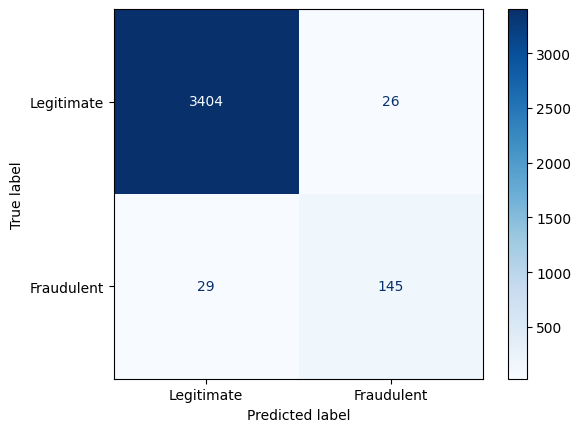

In [33]:
#uses the sklearn metrics tools to determine the performance of the full text model
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
#displays the report
print("Final Expanded Model Classification Report")
print(
    classification_report(
        y_test,
        y_pred_full,
        target_names=['Legitimate', 'Fraudulent'],
        digits=3
    )
)
#displays the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_full,
    display_labels=['Legitimate', 'Fraudulent'],
    cmap='Blues'
)

In [ ]:
#saves the full text model to the drive for later use
import joblib

joblib.dump(
    full_text_model,
    '/content/drive/MyDrive/expanded_fraud_model.joblib'
)

['/content/drive/MyDrive/expanded_fraud_model.joblib']

In [ ]:
#saves the comparison results chart for later use
comparison.to_csv(
    '/content/drive/MyDrive/expanded_model_cv_results.csv',
    index=False
)

##Conclusion

The notebook looks into whether including additional job posting information could improve fraud detection beyond using only the job description.

Six configurations were evaluated using TF-IDF, logistic regression, and 5 fold cross validation. The experiments showed that compay profile text provided a substantial improvement while only checking whether the company profile existed provided a smaller improvement. Adding company logo information and job requirements and benefits produced further improvements.

The selected expanded model used the job description, company profile, requirements, benefits, and company logo inclusion. On the held back data portion, this model achieved a precision of 0.848, recall of 0.833, and F1 score of 0.841. The results improved over the description only model which had an F1 score of 0.704.

The expanded model correctly identified 145 of 174 fraudulent postings, reduced false negatives from 60 to 29 and reduced false positives from 36 to 26.

The findings suggest that fraudulent posting detection benefits from including multiple pieces of information instead of relying only on the job description.